# Pre-owned Cars: Price Prediction (Regression)

**Steps in this notebook**
1. Import libraries and load data
2. Data analysis (shape, types, summary)
3. Data quality audit (missing, duplicates, invalid values, inconsistent text)
4. Data cleaning (standardise text, remove duplicates, fix invalid values, impute, cap outliers)
5. Feature engineering
6. Exploratory graphs
7. Train and compare regression models
8. Metrics and evaluation graphs
9. Save the model and predict a new car

Put `preowned_cars_messy.csv` in the same folder as this notebook.

## 1. Import libraries and load data

In [1]:
import warnings, joblib, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", None)
os.makedirs("charts", exist_ok=True)

DATA_PATH = "preowned_cars_messy.csv"   
CUR_YEAR = 2026                          

raw = pd.read_csv(DATA_PATH)
raw.head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2099.0,60000.0,70000.0,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007.0,-50000.0,50000.0,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012.0,600000.0,-100.0,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017.0,250000.0,46000.0,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014.0,450000.0,141000.0,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007.0,140000.0,125000.0,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016.0,550000.0,25000.0,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014.0,240000.0,60000.0,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015.0,850000.0,25000.0,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017.0,365000.0,78000.0,CNG,Individual,Manual,First Owner


## 2. Data analysis

In [2]:
print("Shape (rows, columns):", raw.shape)
raw.info()

Shape (rows, columns): (4390, 8)
<class 'pandas.DataFrame'>
RangeIndex: 4390 entries, 0 to 4389
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           4369 non-null   str    
 1   year           4375 non-null   float64
 2   selling_price  4375 non-null   float64
 3   km_driven      4375 non-null   float64
 4   fuel           4370 non-null   str    
 5   seller_type    4370 non-null   str    
 6   transmission   4390 non-null   str    
 7   owner          4370 non-null   str    
dtypes: float64(3), str(5)
memory usage: 274.5 KB


In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
year,4375.0,2013.125943,4.407605,1992.0,2011.0,2014.0,2016.0,2099.0
selling_price,4375.0,503815.847771,577091.288867,-50000.0,204999.0,350000.0,600000.0,8900000.0
km_driven,4375.0,66148.040686,46551.592107,-100.0,35000.0,60000.0,90000.0,806599.0


In [4]:
# Data type of each column and number of unique values
pd.DataFrame({"dtype": raw.dtypes.astype(str), "unique_values": raw.nunique()})

,dtype,unique_values
name,str,1488
year,float64,28
selling_price,float64,446
km_driven,float64,770
fuel,str,7
seller_type,str,5
transmission,str,2
owner,str,5


In [5]:
# Look at the categories - this shows inconsistent spelling/spacing
for c in ["fuel", "seller_type", "transmission", "owner"]:
    print(c, "->", raw[c].unique().tolist(), "\n")

fuel -> ['Petrol', 'Diesel', 'CNG', 'DIESEL', 'LPG', nan, 'PETROL', 'Electric'] 

seller_type -> ['Individual', 'Dealer', nan, 'Trustmark Dealer', ' Individual ', ' Dealer '] 

transmission -> ['Manual', 'Automatic'] 

owner -> ['First Owner', 'Second Owner', 'Fourth & Above Owner', 'Third Owner', nan, 'Test Drive Car'] 



## 3. Data quality audit

In [6]:
quality = pd.DataFrame({
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2)})
display(quality)
print("Exact duplicate rows      :", raw.duplicated().sum())
print("Price <= 0                :", (raw.selling_price <= 0).sum())
print("km_driven < 0             :", (raw.km_driven < 0).sum())
print("Year in the future / <1980:", ((raw.year > CUR_YEAR) | (raw.year < 1980)).sum())
print("km_driven > 250,000       :", (raw.km_driven > 250000).sum())

,missing,missing_%
name,21,0.48
year,15,0.34
selling_price,15,0.34
km_driven,15,0.34
fuel,20,0.46
seller_type,20,0.46
transmission,0,0.00
owner,20,0.46


Exact duplicate rows      : 775
Price <= 0                : 1
km_driven < 0             : 1
Year in the future / <1980: 1
km_driven > 250,000       : 20


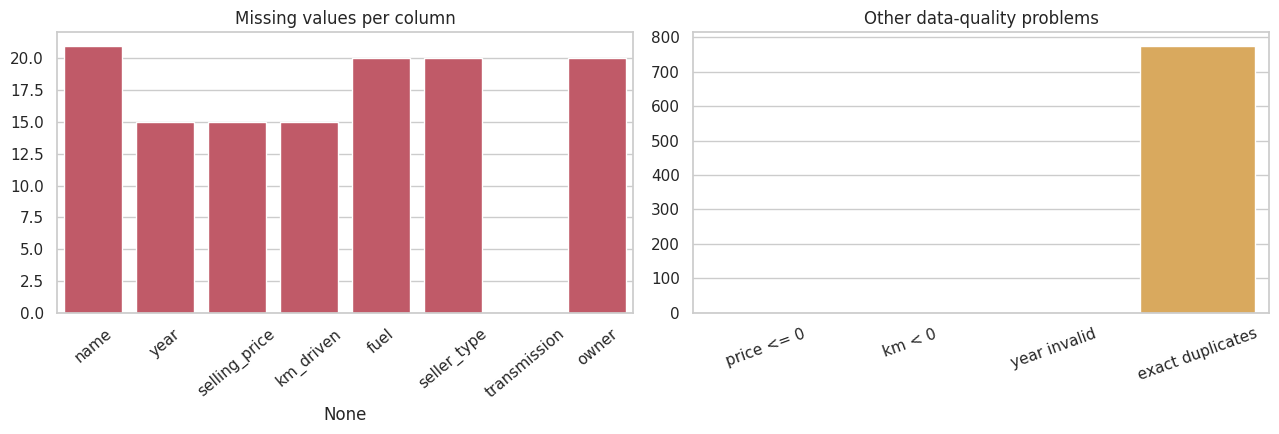

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
miss = raw.isna().sum()
sns.barplot(x=miss.index, y=miss.values, ax=ax[0], color="#d1495b")
ax[0].set_title("Missing values per column"); ax[0].tick_params(axis="x", rotation=40)
inv = {"price <= 0": (raw.selling_price <= 0).sum(),
       "km < 0": (raw.km_driven < 0).sum(),
       "year invalid": ((raw.year > CUR_YEAR) | (raw.year < 1980)).sum(),
       "exact duplicates": raw.duplicated().sum()}
sns.barplot(x=list(inv.keys()), y=list(inv.values()), ax=ax[1], color="#edae49")
ax[1].set_title("Other data-quality problems"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("charts/01_data_quality.png", dpi=130); plt.show()

## 4. Data cleaning
Order matters: standardise text **first**, so `DIESEL` and `Diesel` count as the same value, and only then remove duplicates.

In [8]:
df = raw.copy()
log = {"raw_rows": len(raw)}

# 4a. Standardise text (strip spaces, same capitalisation)
for c in ["name", "fuel", "seller_type", "transmission", "owner"]:
    df[c] = (df[c].astype("string").str.strip()
                   .str.replace(r"\s+", " ", regex=True).str.title())

# 4b. Remove duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log["duplicates_removed"] = before - len(df)

# 4c. Invalid values -> NaN
df.loc[(df.year > CUR_YEAR) | (df.year < 1980), "year"] = np.nan
df.loc[df.km_driven < 0, "km_driven"] = np.nan
df.loc[df.selling_price <= 0, "selling_price"] = np.nan

# 4d. Drop rows we cannot repair (no target price or no car name)
before = len(df)
df = df.dropna(subset=["selling_price", "name"]).reset_index(drop=True)
log["dropped_missing_price_or_name"] = before - len(df)

# 4e. Fill remaining gaps: median for numbers, most common value for text
log["imputed"] = df.isna().sum()[lambda s: s > 0].to_dict()
df["year"] = df["year"].fillna(df["year"].median())
df["km_driven"] = df["km_driven"].fillna(df["km_driven"].median())
for c in ["fuel", "seller_type", "owner"]:
    df[c] = df[c].fillna(df[c].mode()[0])

# 4f. Outliers: cap mileage at the 99.5th percentile (high prices are kept: luxury cars are real)
cap = df.km_driven.quantile(0.995)
log["km_cap"] = float(cap); log["km_rows_capped"] = int((df.km_driven > cap).sum())
df["km_driven"] = df["km_driven"].clip(upper=cap)

# 4g. Correct data types
df["year"] = df["year"].astype(int)
for c in ["fuel", "seller_type", "transmission", "owner"]:
    df[c] = df[c].astype("category")
df["name"] = df["name"].astype(str)

log["clean_rows"] = len(df)
log

{'raw_rows': 4390,
 'duplicates_removed': 787,
 'dropped_missing_price_or_name': 36,
 'imputed': {'year': 15,
  'km_driven': 16,
  'fuel': 20,
  'seller_type': 20,
  'owner': 19},
 'km_cap': 250000.0,
 'km_rows_capped': 17,
 'clean_rows': 3567}

In [9]:
# Check: nothing left to fix
print("Missing values left:", df.isna().sum().sum())
print("Duplicates left    :", df.duplicated().sum())
print(df.dtypes)
df.describe().T

Missing values left: 0
Duplicates left    : 8
name                  str
year                int64
selling_price     float64
km_driven         float64
fuel             category
seller_type      category
transmission     category
owner            category
dtype: object


,count,mean,std,min,25%,50%,75%,max
year,3567.0,2012.970563,4.242373,1992.0,2010.0,2013.0,2016.0,2020.0
selling_price,3567.0,475903.886740,511833.248724,20000.0,200000.0,350000.0,600000.0,8900000.0
km_driven,3567.0,68647.050743,43989.947397,1.0,36500.0,60000.0,90000.0,250000.0


## 5. Feature engineering

In [10]:
df["car_age"] = CUR_YEAR - df["year"]
df["brand"] = df["name"].str.split().str[0]
df.loc[df.brand == "Land", "brand"] = "Land Rover"
df["km_per_year"] = df["km_driven"] / df["car_age"].clip(lower=1)
df["age_sq"] = df["car_age"] ** 2
df["log_km"] = np.log1p(df["km_driven"])

# group very rare brands
vc = df["brand"].value_counts()
df["brand"] = df["brand"].where(df["brand"].isin(vc[vc >= 5].index), "Other")

df.to_csv("preowned_cars_clean.csv", index=False)
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,brand,km_per_year,age_sq,log_km
0,Maruti 800 Ac,2013,60000.0,70000.0,Petrol,Individual,Manual,First Owner,13,Maruti,5384.615385,169,11.156265
1,Hyundai Verna 1.6 Sx,2012,600000.0,60000.0,Diesel,Individual,Manual,First Owner,14,Hyundai,4285.714286,196,11.002117
2,Datsun Redigo T Option,2017,250000.0,46000.0,Petrol,Individual,Manual,First Owner,9,Datsun,5111.111111,81,10.736418
3,Honda Amaze Vx I-Dtec,2014,450000.0,141000.0,Diesel,Individual,Manual,Second Owner,12,Honda,11750.000000,144,11.856522
4,Maruti Alto Lx Bsiii,2007,140000.0,125000.0,Petrol,Individual,Manual,First Owner,19,Maruti,6578.947368,361,11.736077


## 6. Exploratory graphs

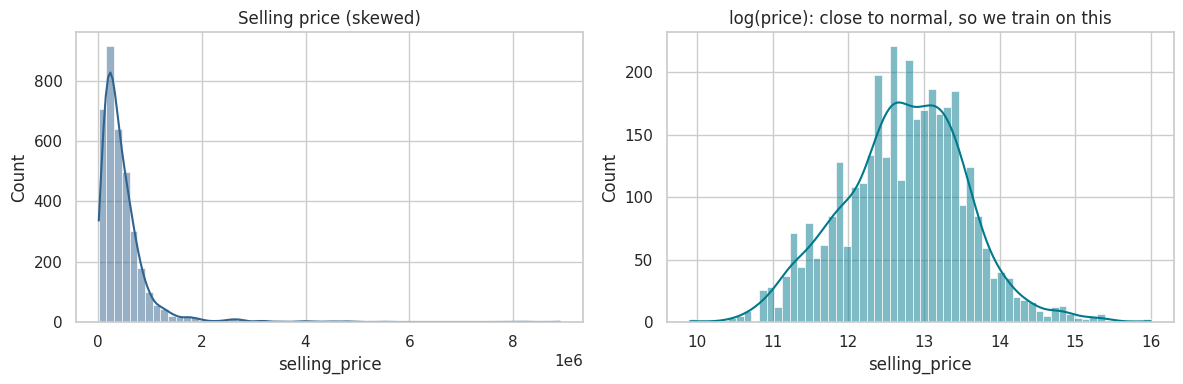

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.selling_price, bins=60, kde=True, ax=ax[0], color="#30638e")
ax[0].set_title("Selling price (skewed)")
sns.histplot(np.log1p(df.selling_price), bins=60, kde=True, ax=ax[1], color="#00798c")
ax[1].set_title("log(price): close to normal, so we train on this")
plt.tight_layout(); plt.savefig("charts/02_price_distribution.png", dpi=130); plt.show()

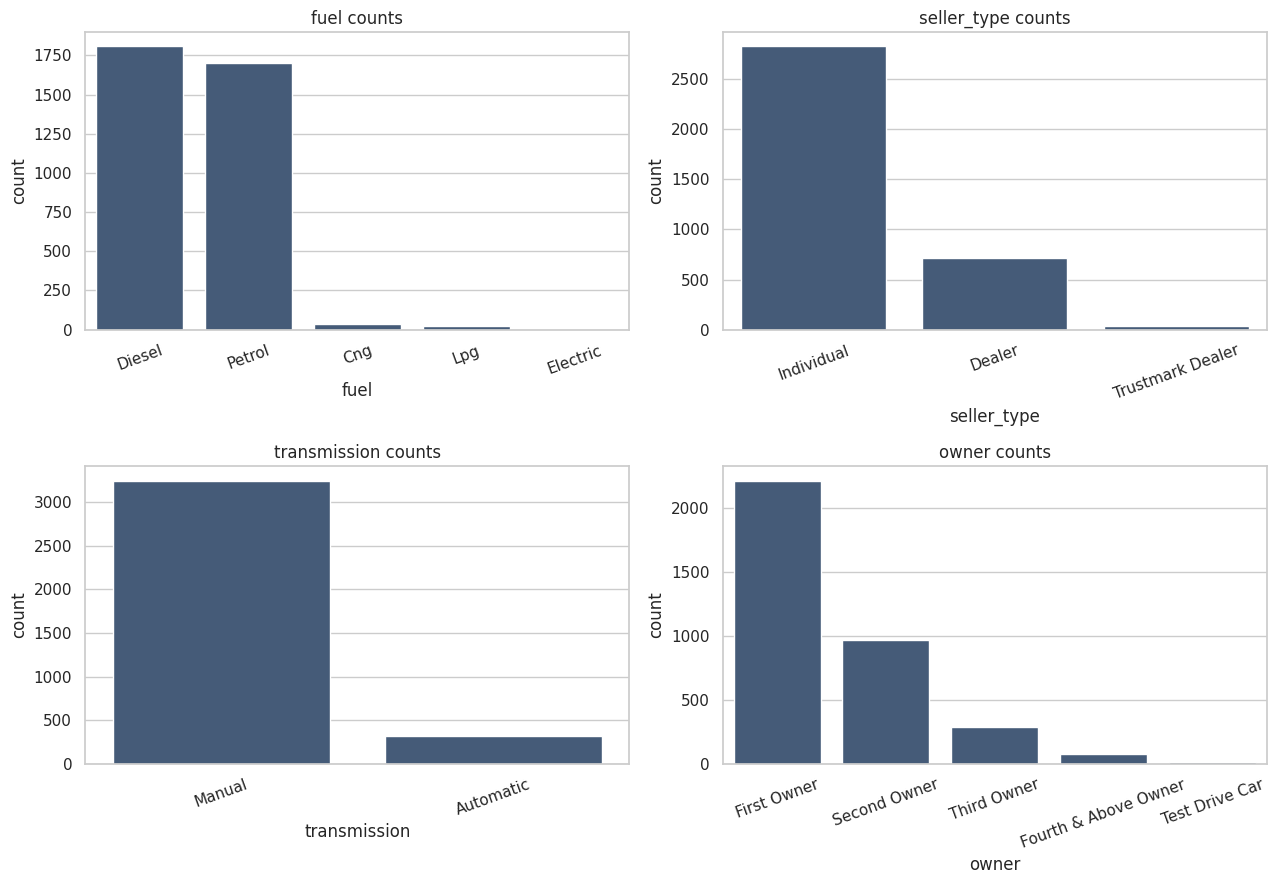

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, c in zip(ax.ravel(), ["fuel", "seller_type", "transmission", "owner"]):
    sns.countplot(data=df, x=c, order=df[c].value_counts().index, ax=a, color="#3d5a80")
    a.set_title(f"{c} counts"); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("charts/03_categorical_counts.png", dpi=130); plt.show()

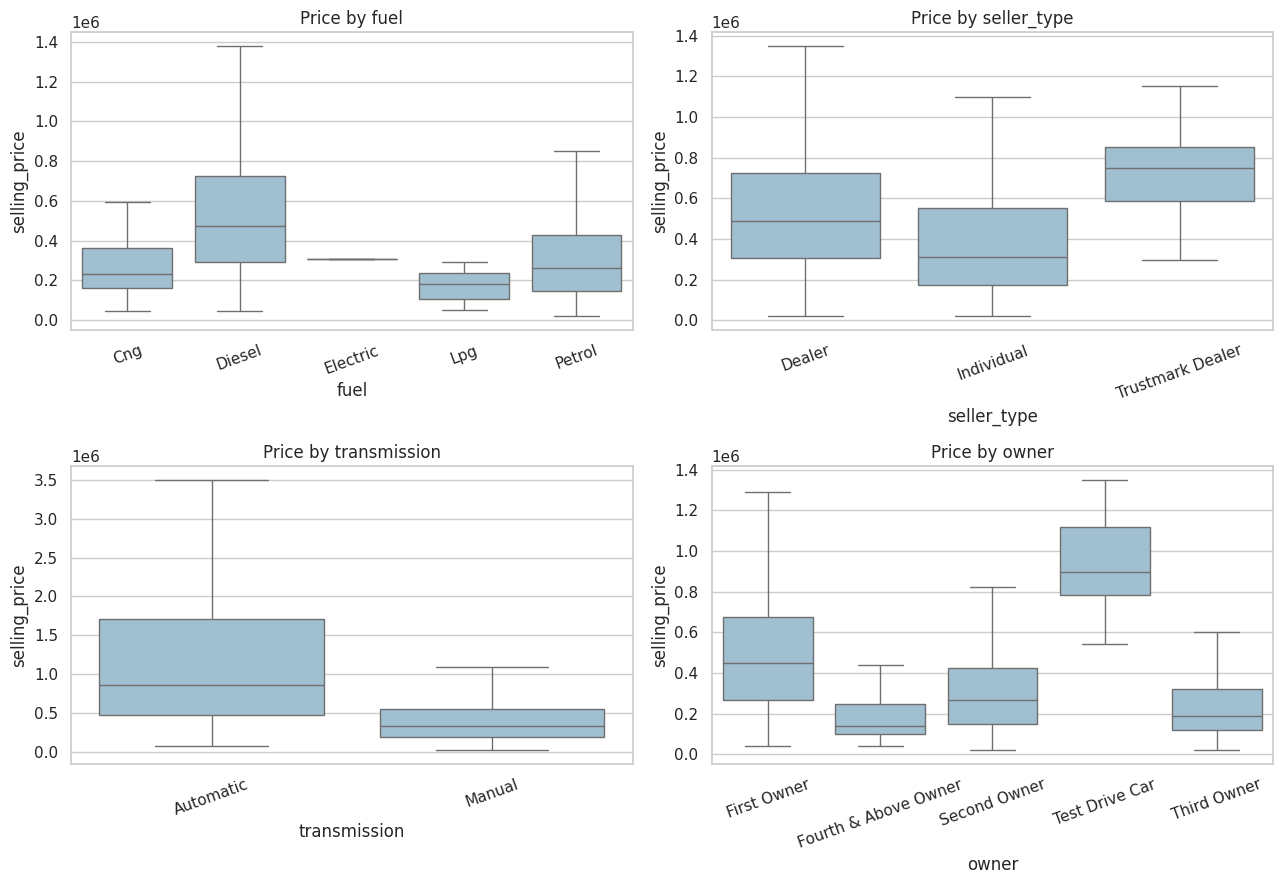

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, c in zip(ax.ravel(), ["fuel", "seller_type", "transmission", "owner"]):
    sns.boxplot(data=df, x=c, y="selling_price", ax=a, showfliers=False, color="#98c1d9")
    a.set_title(f"Price by {c}"); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("charts/04_price_by_category.png", dpi=130); plt.show()

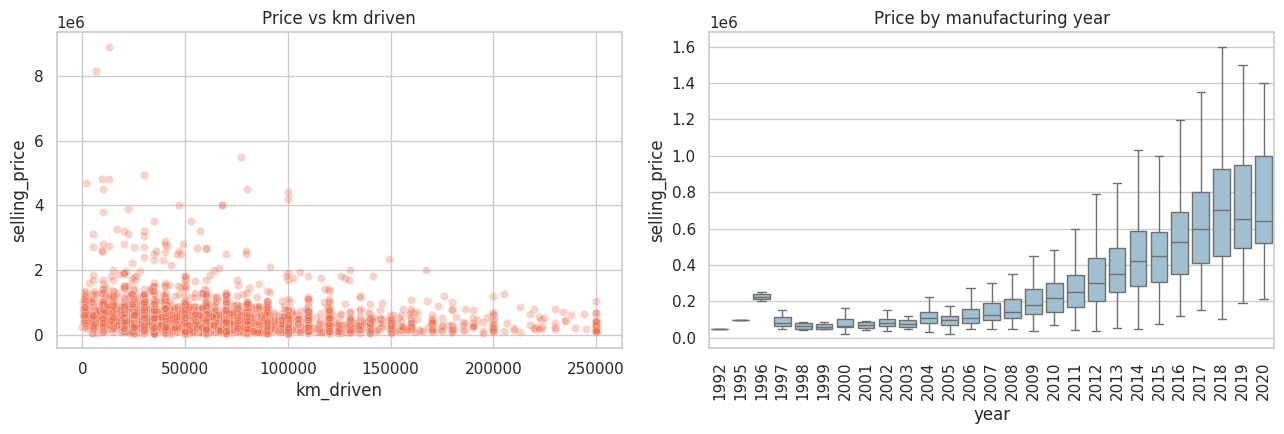

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=.3, ax=ax[0], color="#ee6c4d")
ax[0].set_title("Price vs km driven")
sns.boxplot(data=df, x="year", y="selling_price", showfliers=False, ax=ax[1], color="#98c1d9")
ax[1].set_title("Price by manufacturing year"); ax[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.savefig("charts/05_price_vs_year_km.png", dpi=130); plt.show()

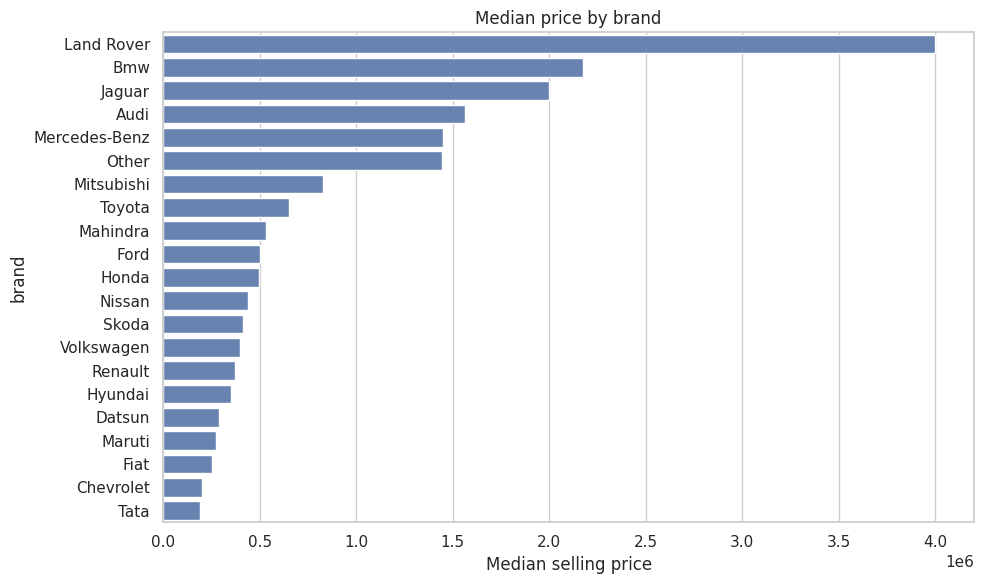

In [15]:
top = df.groupby("brand").selling_price.median().sort_values(ascending=False)
plt.figure(figsize=(10, 6)); sns.barplot(x=top.values, y=top.index, color="#5c80bc")
plt.title("Median price by brand"); plt.xlabel("Median selling price")
plt.tight_layout(); plt.savefig("charts/06_price_by_brand.png", dpi=130); plt.show()

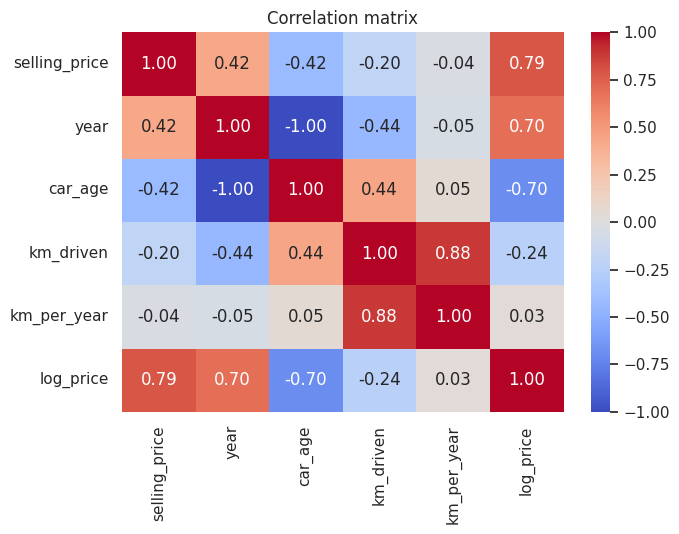

In [16]:
num = df[["selling_price", "year", "car_age", "km_driven", "km_per_year"]].copy()
num["log_price"] = np.log1p(num.selling_price)
plt.figure(figsize=(7, 5.5)); sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout()
plt.savefig("charts/07_correlation.png", dpi=130); plt.show()

## 7. Train and compare models
- Target = **log(price)**, because prices are very skewed. Predictions are converted back to rupees for the metrics.
- The words in the car name (model, engine, trim such as "VXI" or "Diesel") become TF-IDF text features.
- 80% train / 20% test, plus 5-fold cross-validation.

In [17]:
X = df[["name", "brand", "fuel", "seller_type", "transmission", "owner",
        "car_age", "age_sq", "log_km", "km_per_year"]].copy()
for c in ["fuel", "seller_type", "transmission", "owner"]:
    X[c] = X[c].astype(str)
y = np.log1p(df["selling_price"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cat_cols = ["brand", "fuel", "seller_type", "transmission", "owner"]
num_cols = ["car_age", "age_sq", "log_km", "km_per_year"]
pre = ColumnTransformer([
    ("txt", TfidfVectorizer(token_pattern=r"[^ ]+", sublinear_tf=True), "name"),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)])

def metrics(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return dict(R2_log=r2_score(y_true_log, y_pred_log), R2=r2_score(yt, yp),
                MAE=mean_absolute_error(yt, yp),
                RMSE=float(np.sqrt(mean_squared_error(yt, yp))),
                MAPE=float(np.mean(np.abs((yt - yp) / yt)) * 100))

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=0.3)": Ridge(alpha=0.3),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
kf = KFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    p = Pipeline([("pre", pre), ("m", m)])
    cv = cross_val_score(p, X_train, y_train, cv=kf, scoring="r2").mean()
    p.fit(X_train, y_train)
    r = metrics(y_test, p.predict(X_test)); r.update(Model=name, CV_R2_log=cv)
    rows.append(r)
results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,R2_log,R2,MAE,RMSE,MAPE,CV_R2_log
Model,,,,,,
Linear Regression,0.850,0.802,84269.560,190581.814,21.671,0.844
Ridge (alpha=0.3),0.881,0.879,78784.003,149027.730,20.854,0.888
Random Forest,0.825,0.752,99662.488,212894.300,24.286,0.842
Gradient Boosting,0.806,0.690,112674.596,238395.469,27.286,0.831


In [18]:
# Tune Ridge alpha
search = RandomizedSearchCV(Pipeline([("pre", pre), ("m", Ridge())]),
    {"m__alpha": [0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1, 2]},
    n_iter=8, cv=kf, scoring="r2", random_state=42, n_jobs=-1)
search.fit(X_train, y_train)
print("Best params:", search.best_params_, "| CV R2 (log):", round(search.best_score_, 4))

r = metrics(y_test, search.best_estimator_.predict(X_test))
r.update(Model="Ridge (tuned)", CV_R2_log=search.best_score_)
results = pd.concat([results, pd.DataFrame([r]).set_index("Model")])
results.round(3)

Best params: {'m__alpha': 0.8} | CV R2 (log): 0.8898


,R2_log,R2,MAE,RMSE,MAPE,CV_R2_log
Model,,,,,,
Linear Regression,0.850,0.802,84269.560,190581.814,21.671,0.844
Ridge (alpha=0.3),0.881,0.879,78784.003,149027.730,20.854,0.888
Random Forest,0.825,0.752,99662.488,212894.300,24.286,0.842
Gradient Boosting,0.806,0.690,112674.596,238395.469,27.286,0.831
Ridge (tuned),0.881,0.864,79736.879,157985.565,20.995,0.890


## 8. Metrics and evaluation graphs

In [19]:
final_name = results["R2"].idxmax()
final = (search.best_estimator_ if final_name == "Ridge (tuned)"
         else Pipeline([("pre", pre), ("m", models[final_name])]).fit(X_train, y_train))
print("Final model:", final_name)

pred_log = final.predict(X_test)
final_metrics = metrics(y_test, pred_log)
print(f"R2 (price scale): {final_metrics['R2']:.3f}")
print(f"MAE : Rs {final_metrics['MAE']:,.0f}")
print(f"RMSE: Rs {final_metrics['RMSE']:,.0f}")
print(f"MAPE: {final_metrics['MAPE']:.1f}%")
results.round(3).to_csv("model_metrics.csv")

Final model: Ridge (alpha=0.3)
R2 (price scale): 0.879
MAE : Rs 78,784
RMSE: Rs 149,028
MAPE: 20.9%


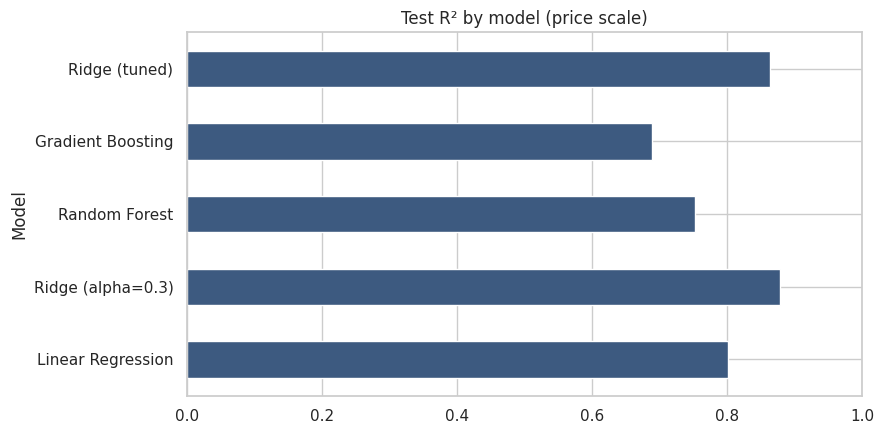

In [20]:
plt.figure(figsize=(9, 4.5)); results["R2"].plot(kind="barh", color="#3d5a80")
plt.title("Test R² by model (price scale)"); plt.xlim(0, 1)
plt.tight_layout(); plt.savefig("charts/08_model_comparison.png", dpi=130); plt.show()

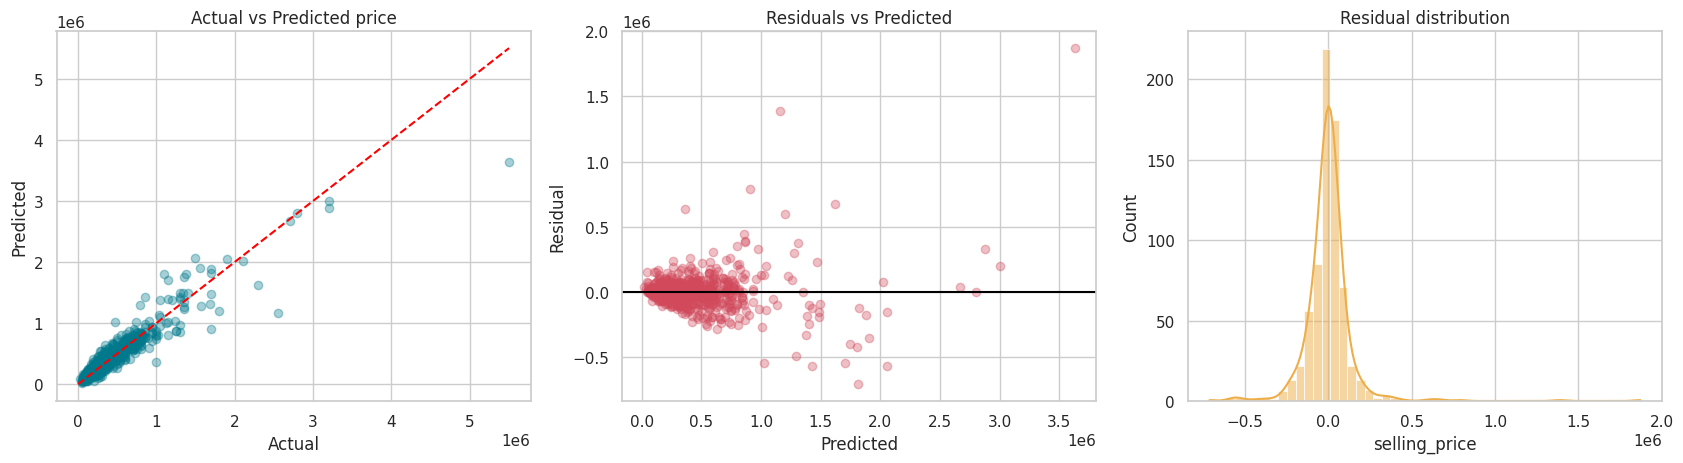

In [21]:
yt, yp = np.expm1(y_test), np.expm1(pred_log)
resid = yt - yp
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].scatter(yt, yp, alpha=.35, color="#00798c"); lim = [0, max(yt.max(), yp.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs Predicted price")
ax[1].scatter(yp, resid, alpha=.35, color="#d1495b"); ax[1].axhline(0, color="k")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals vs Predicted")
sns.histplot(resid, bins=50, kde=True, ax=ax[2], color="#edae49"); ax[2].set_title("Residual distribution")
plt.tight_layout(); plt.savefig("charts/09_actual_vs_predicted.png", dpi=130); plt.show()

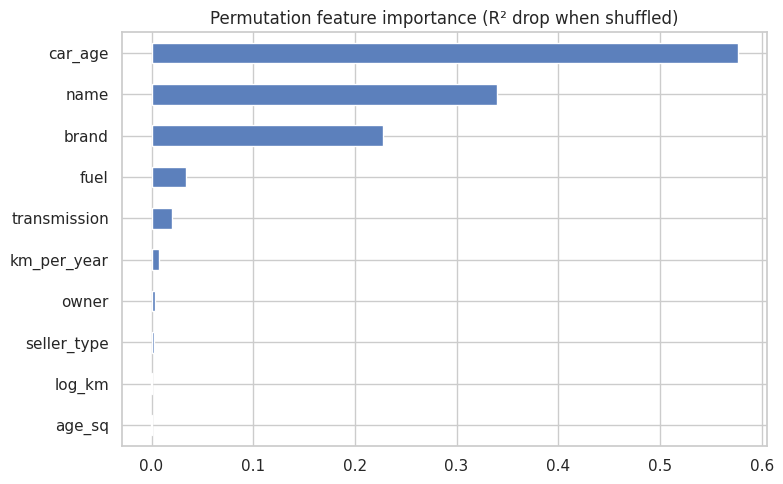

In [22]:
pi = permutation_importance(final, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(8, 5)); imp.plot(kind="barh", color="#5c80bc")
plt.title("Permutation feature importance (R² drop when shuffled)")
plt.tight_layout(); plt.savefig("charts/10_feature_importance.png", dpi=130); plt.show()

## 9. Save the model and predict a new car

In [23]:
joblib.dump(final, "car_price_model.joblib")

def predict_price(name, year, km_driven, fuel, seller_type, transmission, owner):
    brand = name.strip().split()[0].title()
    if brand not in set(X["brand"]): brand = "Other"
    age = CUR_YEAR - year
    row = pd.DataFrame([{
        "name": name.strip().title(), "brand": brand, "fuel": fuel.title(),
        "seller_type": seller_type.title(), "transmission": transmission.title(),
        "owner": owner.title(), "car_age": age, "age_sq": age ** 2,
        "log_km": np.log1p(km_driven), "km_per_year": km_driven / max(age, 1)}])
    return float(np.expm1(final.predict(row))[0])

price = predict_price("Maruti Swift Dzire VDI", 2015, 7000q0, "Diesel", "Individual", "Manual", "First Owner")
print(f"Estimated price: Rs {price:,.0f}")

Estimated price: Rs 482,005
